In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from alerce.core import Alerce
client = Alerce()

In [ ]:
#Another ZTF object to query, not used in this notebook, but can be used to test the code
# object_info = client.query_objects(
#     oid = "ZTF18abkkgap",
#     survey = "ztf",
#     format = "pandas"
# )
# DataFrame = pd.DataFrame(object_info)
# DataFrame.head()


,oid,ndethist,ncovhist,mjdstarthist,mjdendhist,corrected,stellar,ndet,g_r_max,g_r_max_corr,...,lastmjd,deltajd,meanra,meandec,sigmara,sigmadec,class,classifier,probability,step_id_corr
0,ZTF18abkkgap,1560,1965,58244.469526,61030.141007,True,False,1211,None,None,...,61030.141007,2699.780463,298.866511,76.031452,0.008662,0.002091,None,None,None,27.5.7a32.dev1


In [120]:

lc = client.query_lightcurve("ZTF18aasycma", format = "pandas", survey="ztf")
lc_detections = lc["detections"]
detections_list = lc_detections.iloc[0]
df = pd.DataFrame(detections_list)
df.head()

,tid,mjd,candid,fid,pid,diffmaglim,isdiffpos,nid,distnr,magpsf,...,magapbig,sigmagapbig,rfid,has_stamp,corrected,dubious,candid_alert,step_id_corr,phase,parent_candid
0,ztf,58248.295764,494295765115010002,2,494295765115,20.3498,-1,494,0.622996,18.0650,...,17.9108,0.0493,NaN,False,True,False,None,bulk_1.0.0,0.0,5.222964e+17
1,ztf,58252.354224,498354226215015002,2,498354226215,20.7332,1,498,0.181422,17.9014,...,18.0065,0.0518,NaN,False,True,False,None,bulk_1.0.0,0.0,5.222964e+17
2,ztf,58255.273380,501273376215010000,2,501273376215,20.6090,-1,501,0.256945,18.1138,...,18.1065,0.0598,NaN,False,True,False,None,bulk_1.0.0,0.0,5.222964e+17
3,ztf,58255.294097,501294095115010000,2,501294095115,20.5503,-1,501,0.609748,18.2494,...,18.1795,0.0636,NaN,False,True,False,None,bulk_1.0.0,0.0,5.222964e+17
4,ztf,58258.253414,504253415115015000,2,504253415115,20.4893,1,504,0.152636,17.5950,...,17.6200,0.0420,NaN,False,True,False,None,bulk_1.0.0,0.0,5.342531e+17


In [121]:
df["fid"].unique()
#fid: 1 = g 2 = r 3 = i
g_df = df[df["fid"] == 1]
r_df = df[df["fid"] == 2]
i_df = df[df["fid"] == 3]

print(len(g_df), len(r_df), len(i_df))


705 626 2


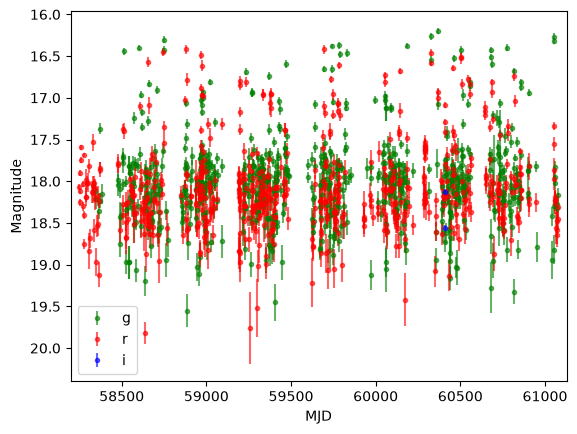

In [122]:
mjdstarthist = df["mjd"].min() - 50
mjdendhist = df["mjd"].max() + 50

fig, axs = plt.subplots()
axs.set_xlabel("MJD")
axs.set_ylabel("Magnitude")
axs.set_xlim(mjdstarthist, mjdendhist)
axs.errorbar(g_df["mjd"], g_df["magpsf"], yerr=g_df["sigmapsf"], fmt="o", label="g", color="green", ms = 3, alpha = 0.6)
axs.errorbar(r_df["mjd"], r_df["magpsf"], yerr=r_df["sigmapsf"], fmt="o", label="r", color="red",  ms = 3, alpha = 0.6)
if(len(i_df) > 0):
    axs.errorbar(i_df["mjd"], i_df["magpsf"], yerr=i_df["sigmapsf"], fmt="o", label="i", color="blue", ms = 3, alpha = 0.6)
axs.legend()
axs.invert_yaxis()